# You tried 50 models: is the winner real?

**Fifty settings, one backtest, one winner, ahead by 0.2%. Nine others cannot be told apart from it, it wins a third of the time when the products are drawn again, and the next year it comes tenth.**

A supplier forecasts next year's monthly patient numbers for 114 medical products. The usual way to choose a model is to try many settings on a backtest and report the best. The trouble is that the best of 50 is partly the luckiest of 50. TimeGym runs every setting on the same cases with the same checks and keeps each case's score, and that is what it takes to ask how much of a lead is luck.

*Data: monthly patient counts for medical products, 2000 to 2006, from the Monash Time Series Forecasting Archive, CC BY 4.0 ([source and license](data/README.md#hospital-patients)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

from timegym import NaiveForecaster, Pipeline, cases_from_series
from timegym.statistics import paired_t_interval
from timegym.target import LogTransform

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## The job

Seven years of monthly counts for each product. We choose a model on the forecast of year 6, made from years 1 to 5. Year 7 is kept aside to see how the choice turns out.

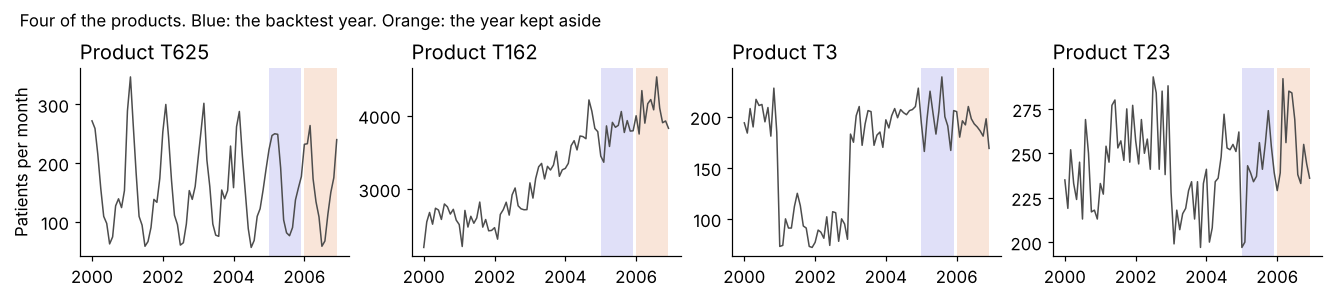

114 products, 84 months, January 2000 to December 2006.


In [2]:
patients = load("hospital-patients").astype(float)
months = patients.index.to_timestamp()

fig, axes = plt.subplots(1, 4, figsize=(12, 2.6), layout="constrained")
for ax, product in zip(axes, ["T625", "T162", "T3", "T23"]):
    ax.plot(months, patients[product], color="0.3", linewidth=1)
    ax.axvspan(months[60], months[71], color="#0000CC", alpha=0.12, linewidth=0)
    ax.axvspan(months[72], months[83], color="#DD5500", alpha=0.15, linewidth=0)
    ax.set_title(f"Product {product}")
    ax.set_xticks(months[::24], [f"{month:%Y}" for month in months[::24]])
axes[0].set_ylabel("Patients per month")
fig.suptitle("Four of the products. Blue: the backtest year. Orange: the year kept aside", x=0.01, ha="left", fontsize=11)
plt.show()
print(f"{patients.shape[1]} products, {len(patients)} months, {months[0]:%B %Y} to {months[-1]:%B %Y}.")

The products are not alike: some have a season, some grow, some jump to a new level, some just wobble.

## Fifty settings, one backtest

The sweep is the kind anyone might run: six families of forecaster, each with a few values of its settings.

- **Linear and ridge regression** on the last 6, 12, 13, 18 or 24 months, on the counts or on their logarithm (20 settings).
- **Nearest neighbors**: find the 3, 5 or 10 stretches of history most like the last 6, 12, 18 or 24 months and average what came next (12).
- **A decision tree** of depth 2, 3 or 5 on the last 12 or 24 months (6).
- **Smoothing**: a running average that gives the newest month a weight of `alpha`, for six values of `alpha` (6).
- **The average** of the last 3, 6, 12 or 24 months (4).
- **Last month** and **same month last year** (2).

Every setting forecasts year 6 for every product. The score is the scaled error: the average miss divided by the product's usual month-to-month change, so that a product with 3,000 patients a month counts as much as one with 100. Lower is better.

In [3]:
class Smoothing:
    def __init__(self, alpha):
        self.alpha = alpha

    def fit(self, history):
        values = np.asarray(history, dtype=float).ravel()
        level = values[0]
        for value in values[1:]:
            level = self.alpha * value + (1 - self.alpha) * level
        self.level_ = level
        return self

    def predict(self, dates):
        return np.full(len(dates), self.level_)


class RecentAverage:
    def __init__(self, months):
        self.months = months

    def fit(self, history):
        self.level_ = float(np.asarray(history)[-self.months:].mean())
        return self

    def predict(self, dates):
        return np.full(len(dates), self.level_)


settings = {}
for look_back, (model, make), log in itertools.product(
        [6, 12, 13, 18, 24], [("Linear", LinearRegression), ("Ridge", lambda: Ridge(alpha=10.0))], [False, True]):
    settings[f"{model} regression on {look_back} months{', log' if log else ''}"] = Pipeline(
        make(), window_length=look_back, target_transform=LogTransform() if log else None)
for look_back, neighbors in itertools.product([6, 12, 18, 24], [3, 5, 10]):
    settings[f"{neighbors} nearest neighbors on {look_back} months"] = Pipeline(
        KNeighborsRegressor(neighbors), window_length=look_back)
for look_back, depth in itertools.product([12, 24], [2, 3, 5]):
    settings[f"Tree of depth {depth} on {look_back} months"] = Pipeline(
        DecisionTreeRegressor(max_depth=depth, random_state=0), window_length=look_back)
for alpha in [0.1, 0.2, 0.3, 0.5, 0.7, 0.9]:
    settings[f"Smoothing, alpha {alpha}"] = Pipeline(Smoothing(alpha))
for look_back in [3, 6, 12, 24]:
    settings[f"Average of last {look_back} months"] = Pipeline(RecentAverage(look_back))
settings["Last month"] = Pipeline(NaiveForecaster(strategy="last"))
settings["Same month last year"] = Pipeline(NaiveForecaster(strategy="seasonal", period=12))


def year_ahead(first_month):
    # One case per product: forecast 12 months from all the months before `first_month`.
    return [case for product in patients.columns
            for case in cases_from_series(patients[[product]], origins=[first_month], horizon=12, name=product)]


def scaled_errors(cases):
    # Every setting on the same cases: one row per product, one column per setting.
    table, problems = {}, 0
    for name, pipeline in settings.items():
        run = pipeline.run(cases=cases)
        counts = run.report.summary["status_counts"]
        problems += counts["ERROR"] + counts["FAIL"]
        table[name] = [entry.result.metrics["mase"] for entry in run.cases]
    return pd.DataFrame(table, index=patients.columns), problems


backtest, problems = scaled_errors(year_ahead(60))   # year 6 from years 1 to 5
ranking = backtest.mean().sort_values()
winner = ranking.index[0]
display(ranking.head(10).round(3).to_frame("Scaled error on the backtest").rename_axis("Setting"))
print(f"{len(settings)} settings, {len(backtest)} products each. Errors and failed output checks: {problems}.")
print(f"Winner: {winner}. Ahead of the second by {100 * (1 - ranking.iloc[0] / ranking.iloc[1]):.1f}%,")
print(f"  and of 'Same month last year' by {100 * (1 - ranking.iloc[0] / ranking['Same month last year']):.1f}%.")
print(f"Half of the settings score above {ranking.median():.2f}; the worst scores {ranking.iloc[-1]:.2f}.")
assert len(settings) == 50 and problems == 0 and winner == "Smoothing, alpha 0.2"

,Scaled error on the backtest
Setting,
"Smoothing, alpha 0.2",0.895
"Smoothing, alpha 0.3",0.897
10 nearest neighbors on 18 months,0.911
10 nearest neighbors on 12 months,0.912
5 nearest neighbors on 18 months,0.915
Same month last year,0.919
Average of last 12 months,0.919
Average of last 3 months,0.920
Average of last 6 months,0.927


50 settings, 114 products each. Errors and failed output checks: 0.
Winner: Smoothing, alpha 0.2. Ahead of the second by 0.2%,
  and of 'Same month last year' by 2.6%.
Half of the settings score above 1.05; the worst scores 2.29.


All 5,700 forecasts came back clean, so no setting is high or low in the table because it quietly broke.

The report writes itself: *we tried 50 settings; the best is smoothing with alpha 0.2, which beats "same month last year" by 2.6%.* Before sending it, two questions.

## Is the lead real?

The winner's score is an average over 114 products, and it beats the second by 0.2%. Because every setting ran on the same products, we can take each rival's score minus the winner's, product by product, and ask whether the average of those 114 differences is clearly above zero. `paired_t_interval` gives the average and a 95% interval for it.

,Winner's lead,Low,High
Setting,,,
"Smoothing, alpha 0.3",0.002,-0.011,0.014
10 nearest neighbors on 18 months,0.016,-0.038,0.070
10 nearest neighbors on 12 months,0.017,-0.040,0.075
5 nearest neighbors on 18 months,0.020,-0.037,0.078
Same month last year,0.024,-0.029,0.077
Average of last 3 months,0.025,-0.002,0.053
"Smoothing, alpha 0.5",0.035,-0.002,0.072
3 nearest neighbors on 18 months,0.057,-0.005,0.119
5 nearest neighbors on 12 months,0.062,-0.008,0.133


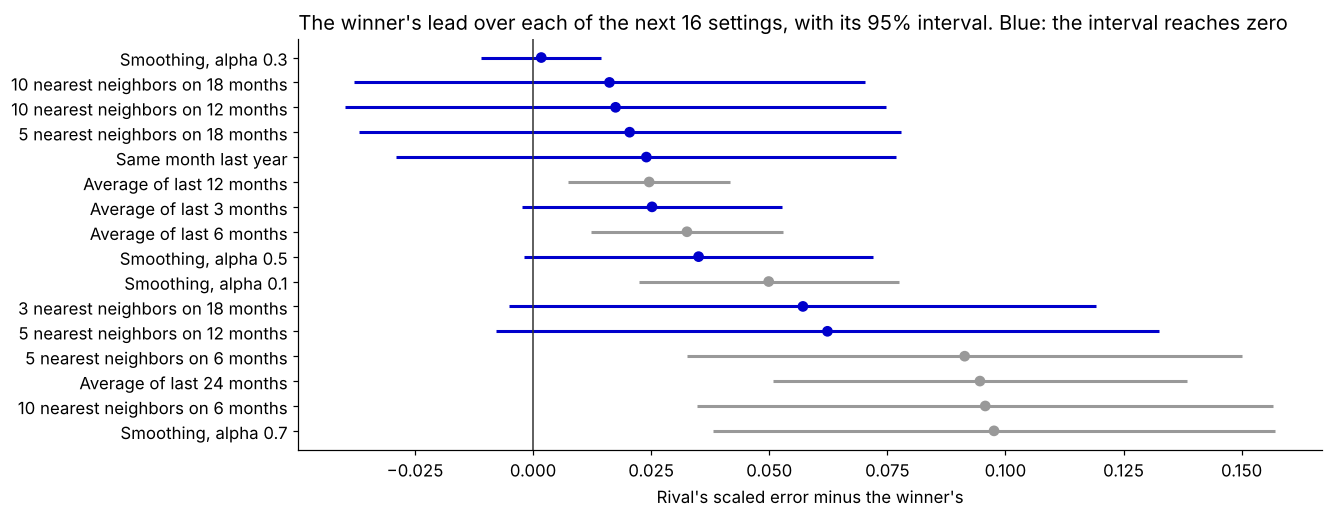

9 of the other 49 settings cannot be told apart from the winner.


In [4]:
def lead_over(rival, scores=backtest):
    interval = paired_t_interval((scores[rival] - scores[winner]).to_numpy())
    return {"Winner's lead": interval["mean"], "Low": interval["ci95"][0], "High": interval["ci95"][1]}


leads = pd.DataFrame({rival: lead_over(rival) for rival in ranking.index[1:]}).T
tied = list(leads.index[leads["Low"] <= 0])
display(leads.loc[tied].round(3).rename_axis("Setting"))

shown = leads.iloc[:16]
fig, ax = plt.subplots(figsize=(12, 4.6), layout="constrained")
colors = ["#0000CC" if rival in tied else "0.6" for rival in shown.index]
ax.hlines(range(len(shown)), shown["Low"], shown["High"], color=colors, linewidth=2)
ax.scatter(shown["Winner's lead"], range(len(shown)), color=colors, zorder=3)
ax.axvline(0, color="0.2", linewidth=1)
ax.set_yticks(range(len(shown)), shown.index)
ax.invert_yaxis()
ax.set(title="The winner's lead over each of the next 16 settings, with its 95% interval. Blue: the interval reaches zero",
       xlabel="Rival's scaled error minus the winner's")
plt.show()
print(f"{len(tied)} of the other {len(leads)} settings cannot be told apart from the winner.")
assert len(tied) == 9 and "Same month last year" in tied and "10 nearest neighbors on 12 months" in tied

Nine settings cannot be told apart from the winner on this backtest. "Same month last year" is one of them: the winner's lead over it is 0.024, with an interval from about minus 0.03 to plus 0.08. The 2.6% in the draft report is inside the noise. For the other 40 settings the interval stays above zero: on these products, in this year, the winner is ahead of them.

## Would the same setting win again?

A second way to ask, with nothing but the table of per-product scores. Suppose the supplier had a slightly different set of products: draw 114 products from ours at random, allowing repeats, and pick the winner again. Do that 2,000 times.

And a direct measure of how flattering a winning score is: choose the winner on one half of the products, then score that same setting on the other half, which had no say in the choice.

In [5]:
rng = np.random.default_rng(0)
scores, products = backtest.to_numpy(), len(backtest)
wins, flattery = np.zeros(len(settings), dtype=int), []
for _ in range(2000):
    drawn = rng.integers(0, products, products)
    wins[scores[drawn].mean(axis=0).argmin()] += 1
    shuffled = rng.permutation(products)
    chose, fresh = shuffled[: products // 2], shuffled[products // 2:]
    pick = scores[chose].mean(axis=0).argmin()
    flattery.append(scores[fresh, pick].mean() - scores[chose, pick].mean())

share = (100 * pd.Series(wins, index=backtest.columns) / 2000).sort_values(ascending=False)
display(share[share >= 1].round(0).astype(int).to_frame("Wins (% of 2,000 draws)").rename_axis("Setting"))
worse = 100 * np.mean(flattery) / ranking.iloc[0]
print(f"Chosen on one half of the products, scored on the other half: {worse:.1f}% worse, on average.")
assert share.index[0] == winner and 30 < share.iloc[0] < 40 and (share >= 5).sum() == 6 and 3.5 < worse < 5.5

,"Wins (% of 2,000 draws)"
Setting,
"Smoothing, alpha 0.2",34
"Smoothing, alpha 0.3",25
10 nearest neighbors on 12 months,13
5 nearest neighbors on 18 months,10
10 nearest neighbors on 18 months,9
Same month last year,8


Chosen on one half of the products, scored on the other half: 4.1% worse, on average.


The backtest's winner wins about one draw in three. Six different settings each win at least one draw in twenty, and all six are in the tied group.

The second number is the one to remember. Chosen on 57 products, a winning score flatters its setting by about 4%, simply because it was the winner. With all 114 products the effect is smaller, but it does not go away, and it is the size of the 2.6% lead we were about to report.

## The year kept aside

Now the test nobody can run at the time of the decision: the same 50 settings forecast year 7, from years 1 to 6.

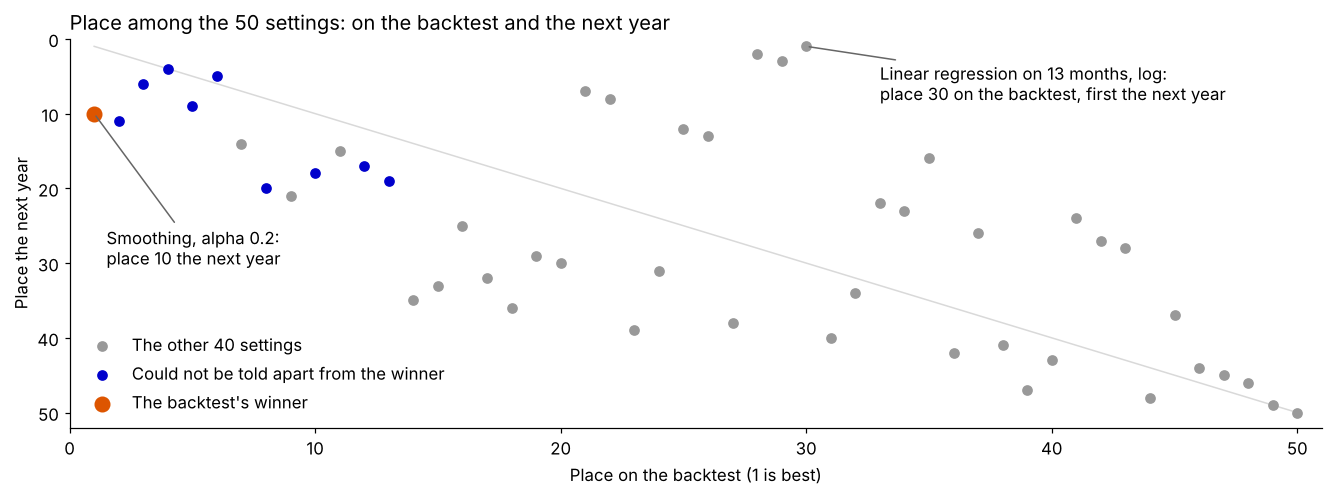

,Backtest place,Next-year place,Next-year score
Setting,,,
"Smoothing, alpha 0.2",1,10,0.975
"Smoothing, alpha 0.3",2,11,0.977
10 nearest neighbors on 18 months,3,6,0.958
10 nearest neighbors on 12 months,4,4,0.954
5 nearest neighbors on 18 months,5,9,0.971
Same month last year,6,5,0.957
Average of last 3 months,8,20,1.003
"Smoothing, alpha 0.5",10,18,1.001
3 nearest neighbors on 18 months,12,17,1.000


The backtest's winner comes in place 10 the next year.
The next year's best three were in places 28, 29, 30 on the backtest.
Against 'Same month last year', the winner is 1.9% worse the next year.


In [6]:
next_year, problems = scaled_errors(year_ahead(72))   # year 7 from years 1 to 6
later = next_year.mean()
ranks = pd.DataFrame({"Backtest": ranking.rank().astype(int), "Next year": later.rank().astype(int)[ranking.index]})
best_later = later.idxmin()

fig, ax = plt.subplots(figsize=(12, 4.4), layout="constrained")
others = [name for name in ranks.index if name not in tied and name != winner]
ax.plot([1, 50], [1, 50], color="0.85", linewidth=1, zorder=0)
ax.scatter(ranks.loc[others, "Backtest"], ranks.loc[others, "Next year"], color="0.6", label="The other 40 settings")
ax.scatter(ranks.loc[tied, "Backtest"], ranks.loc[tied, "Next year"], color="#0000CC", label="Could not be told apart from the winner")
ax.scatter(ranks.loc[winner, "Backtest"], ranks.loc[winner, "Next year"], color="#DD5500", s=90, zorder=3, label="The backtest's winner")
ax.annotate(f"{winner}:\nplace {ranks.loc[winner, 'Next year']} the next year", ranks.loc[winner], xytext=(1.5, 28),
            arrowprops={"arrowstyle": "-", "color": "0.4"}, va="center")
ax.annotate(f"{best_later}:\nplace {ranks.loc[best_later, 'Backtest']} on the backtest, first the next year", ranks.loc[best_later],
            xytext=(33, 6), arrowprops={"arrowstyle": "-", "color": "0.4"}, va="center")
ax.set(title="Place among the 50 settings: on the backtest and the next year", xlabel="Place on the backtest (1 is best)",
       ylabel="Place the next year", xlim=(0, 51), ylim=(52, 0))
ax.legend(loc="lower left")
plt.show()

compare = pd.DataFrame({"Backtest place": ranks["Backtest"], "Next-year place": ranks["Next year"],
                        "Next-year score": later[ranking.index].round(3)})
display(compare.loc[[winner, *tied]].rename_axis("Setting"))
top_later = ranks.sort_values("Next year").head(3)
print(f"The backtest's winner comes in place {ranks.loc[winner, 'Next year']} the next year.")
print(f"The next year's best three were in places {', '.join(str(place) for place in sorted(top_later['Backtest']))} on the backtest.")
gap = 100 * (later[winner] / later["Same month last year"] - 1)
print(f"Against 'Same month last year', the winner is {abs(gap):.1f}% {'worse' if gap > 0 else 'better'} the next year.")
assert problems == 0 and ranks.loc[winner, "Next year"] == 10 and top_later["Backtest"].min() >= 28 and 1 < gap < 3

The winner comes tenth. "Same month last year", which it was reported to beat by 2.6%, finishes 1.9% ahead of it.

The three best settings of the next year were in places 28 to 30 on the backtest, among the 40 the interval had put behind the winner. The interval measured one kind of luck: which products we happened to have. It could not measure the other kind, which year we happened to test on, and a backtest of one year has no way to.

The backtest was not useless. The settings at the bottom mostly stayed there, and the tied group all finished in the upper half. What it could not do is put the top in order, and the top is where the decision is made.

## What to report instead

*Ten settings tie; these are the reasons we picked one of them.* The backtest has nothing more to say about the ten, but they are not the same forecaster. The scorecard runs each on generated series of ten patterns with the same shape as our job: five years of history, one year ahead. Those series played no part in the sweep.

In [7]:
candidates = {"Smoothing": winner, "Neighbors": "10 nearest neighbors on 12 months",
              "Same month last year": "Same month last year"}
cards = {label: settings[name].run(history_length=60, horizon=12).scorecard for label, name in candidates.items()}
rows = pd.DataFrame({label: card.table.groupby("title", sort=False)["score"].mean() for label, card in cards.items()})
rows.loc["Whole scorecard"] = [card.score for card in cards.values()]
display(rows.round(0).astype(int).rename_axis("Pattern (score out of 100)"))
print(f"Smoothing is '{winner}'.\nNeighbors is '{candidates['Neighbors']}'.")
assert all(name in [winner, *tied] for name in candidates.values())

,Smoothing,Neighbors,Same month last year
Pattern (score out of 100),,,
Pure noise,92,93,51
Noise around a fixed level,92,93,51
Straight-line trend,47,41,29
Repeating seasonal cycle,22,75,51
Trend + seasonal cycle,17,25,29
Sudden level shift,90,91,54
Mean reversion (AR(1)): shocks fade,88,74,47
Irregular cycles (AR(2)),48,65,31
Random walk: shocks never fade,93,74,61


Smoothing is 'Smoothing, alpha 0.2'.
Neighbors is '10 nearest neighbors on 12 months'.


Three tied settings, three characters.

- **Smoothing** forecasts a flat line. It is close to the best possible on series that only wobble around a level (92) and has no answer to a season (22).
- **Nearest neighbors** follows a season (75), at some cost on series that wander (74 against 93 on a random walk).
- **Same month last year** scores 51 even on pure noise: it repeats last year's noise as if it were a pattern, which doubles the squared error a flat line would make.

None of the three can follow a straight-line trend (47, 41 and 29), and a product like T162 above has one.

These are reasons a person can weigh. A supplier whose costly products are the seasonal ones has a reason to take nearest neighbors; one who wants the calmest forecast for products that only wobble has a reason to take smoothing. Either is a better reason than a lead of 0.2%.

## What TimeGym added

- One set of cases for all 50 settings, with the same output checks. All 11,400 forecasts passed, so no setting owes its place to a failure nobody saw.
- Every case's score kept, not only the average. The interval for a lead, the redraws and the two-halves test are each a few lines on that table.
- `paired_t_interval`, which turned "ahead by 0.2%" into "nine cannot be told apart".
- A scorecard on series the sweep never saw, to tell tied candidates apart by what they can and cannot do.

## Change one thing

- Give the backtest a second year: average `scaled_errors(year_ahead(48))[0]` with `backtest` and run the same cells. Does the tied group shrink?
- Use every product: `load("hospital-patients", full=True)` has 767, most of them with far fewer patients a month.
- Sweep less. Keep only the six smoothing settings and run the two-halves test again: with fewer settings to choose from, the winning score flatters less.
- Scale by the year-on-year change: `scores={"mase_12": partial(mase, seasonality=12)}`, with `mase` from `timegym.metrics` and `partial` from `functools`.

**What this doesn't show.** The intervals treat the 114 products as independent. Products of one supplier in the same year share good and bad months, so the true intervals are wider, if anything. There is one backtest year and one year kept aside; another pair of years would give different places. Nothing here says smoothing is a poor choice: it says the backtest could not tell it from nine others. The scorecard's series are generated and simpler than real ones; it shows what a setting can do, not how it will do on these products.

**Related:** [Case-level uncertainty intervals](../docs/api/diagnostics.md#case-level-uncertainty-intervals) in the reference, [Real-data forecasts](../tutorials/07_real_data_forecasts.ipynb) for cases cut from your own series, and [Quick start](../tutorials/01_quick_start.ipynb), which reads a scorecard step by step. More examples are on the [examples page](../docs/examples.md).